# 11 — Computational efficiency (accuracy versus compute)

The corrected accuracy–compute analysis. **ReMedFiLM FULL appears as its own plotted point**, which the earlier report failed to do.

**Evidence base**

- `reports/tables/phase21_six_model_compute.csv`
- `reports/tables/c2_barr/c2_barr_aggregate.json`
- `reports/audits/phase34_efficiency_result_v1_4.json`

> Execution is `ANALYSIS_ONLY`. Training, new inference and protected TEST access
> are blocked by an installed audit hook (verified below).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


## 11.1 The three verified anchors

| | Parameters | Analytical GMACs | VAL808 macro Dice |
|---|---|---|---|
| GlobalMedFiLM (G) | 3,523,001 | 31.5517 (lower bound) | 0.835079 |
| **ReMedFiLM FULL** | **4,837,420** | **32.4379** (expected conditional) | **0.837290** |

> **Correction.** Earlier report versions quoted **34.72 GMACs** and
> **83.79 % (0.837862)**. 34.72 is the *always-refine* cost; the deployed system
> routes only 24.3 % of cases. 0.837862 appears in no frozen artifact — re-scoring
> the saved masks gives 0.837290, matching Phase 27 and Phase 29 exactly.
> See `SCIENTIFIC_CORRECTIONS.json`.

In [3]:
eff = pd.read_csv(TABLES / "REMEDFILM_EFFICIENCY.csv")
eff.to_string(index=False)

'                      model   params     gmacs        gmacs_semantics  latency_p50_ms              latency_p50_semantics  macro_dice population                                                                  source\n          GlobalMedFiLM (G)  3523001 31.551700 ANALYTICAL_LOWER_BOUND       15.721472 MEASURED_BATCH1_CONTROLLED_FORWARD    0.835079     VAL808 phase21_analytical_mac_count.json / phase34_efficiency_result_v1_4.json\n           ReMedFiLM (FULL)  4837420 32.437902   EXPECTED_CONDITIONAL       18.886640 MEASURED_BATCH1_CONTROLLED_FORWARD    0.837290     VAL808          phase34_parameter_count_contract.json / c2_barr_aggregate.json\n                 DeepLabV3+ 40347041       NaN           NOT_RECORDED             NaN                       NOT_RECORDED    0.827652     VAL808                         reports/tables/phase21_six_model_comparison.csv\nTransformer/MiT-style U-Net 16347777       NaN           NOT_RECORDED             NaN                       NOT_RECORDED    0.82238

In [4]:
c2 = json.loads((REPO / "reports/tables/c2_barr/c2_barr_aggregate.json").read_text(encoding="utf-8"))
g = c2["compute"]["analytical_gmacs_lower_bound"]
print("LITERAL_GLOBAL_ONLY_C1          :", g["LITERAL_GLOBAL_ONLY_C1"])
print("FINAL_A8_C9_EXPECTED_CONDITIONAL:", g["FINAL_A8_C9_EXPECTED_CONDITIONAL"])
print("LITERAL_ALWAYS_REFINE_C2        :", g["LITERAL_ALWAYS_REFINE_C2"])
print()
print("routing fraction used:", 0.243091)
print("expected cost = 31.5517 + 0.243091 * 3.646 = 32.4379")
print("always-refine cost would be 34.78 -> the figure previously quoted 34.72")

LITERAL_GLOBAL_ONLY_C1          : 31.551740928
FINAL_A8_C9_EXPECTED_CONDITIONAL: 32.437902022582854
LITERAL_ALWAYS_REFINE_C2        : 34.782403584

routing fraction used: 0.243091
expected cost = 31.5517 + 0.243091 * 3.646 = 32.4379
always-refine cost would be 34.78 -> the figure previously quoted 34.72


## 11.2 The corrected figure

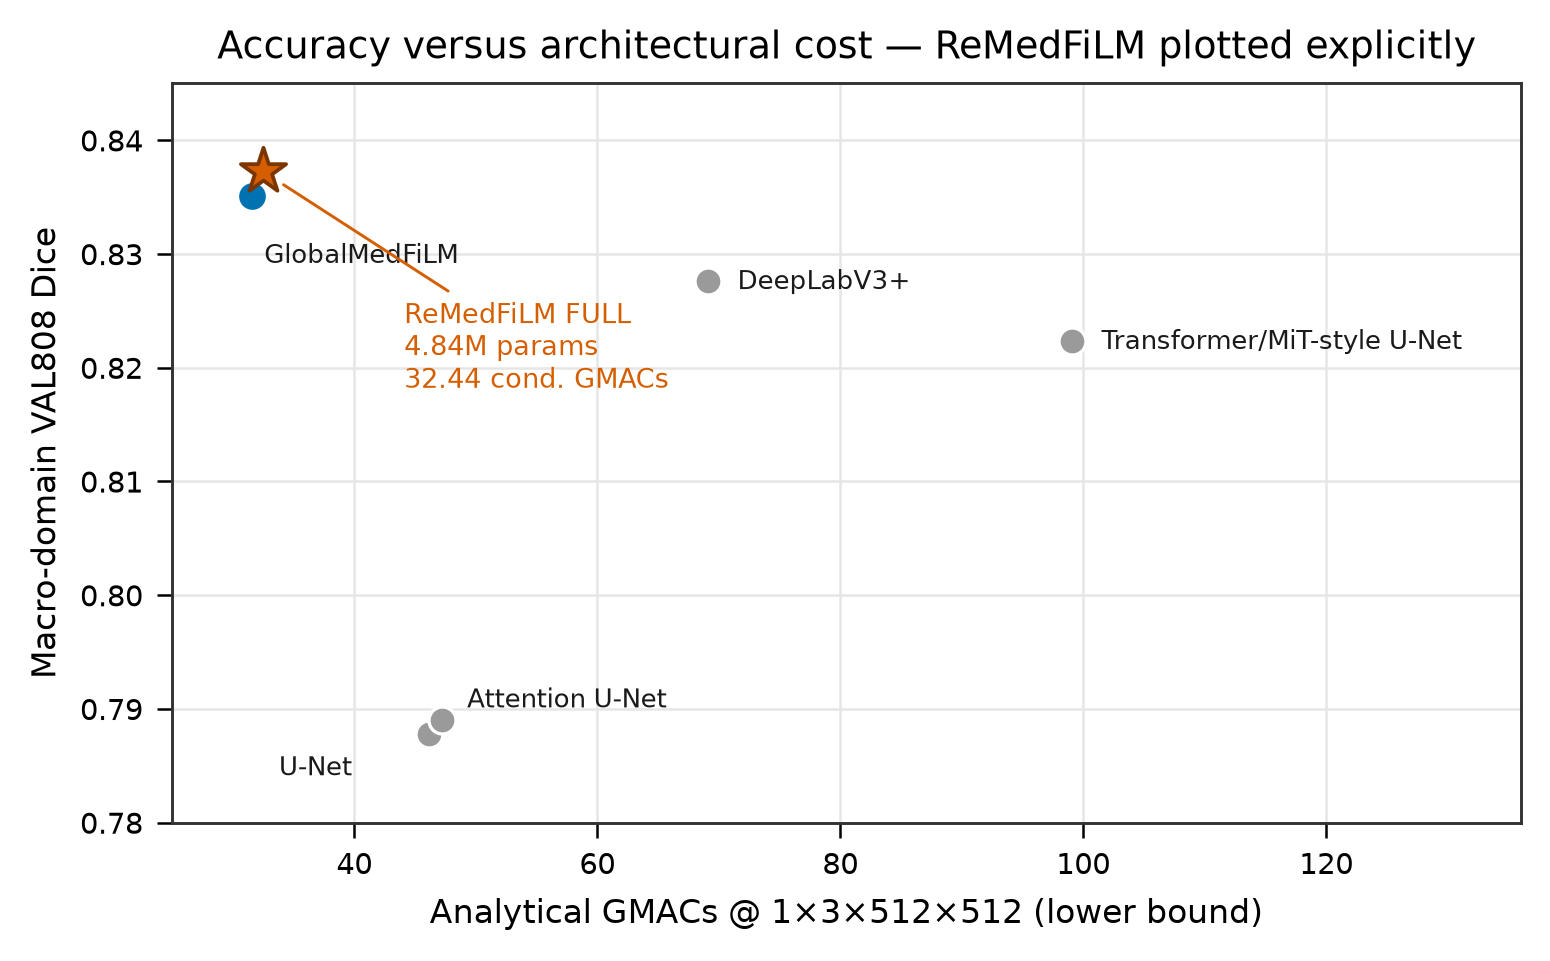

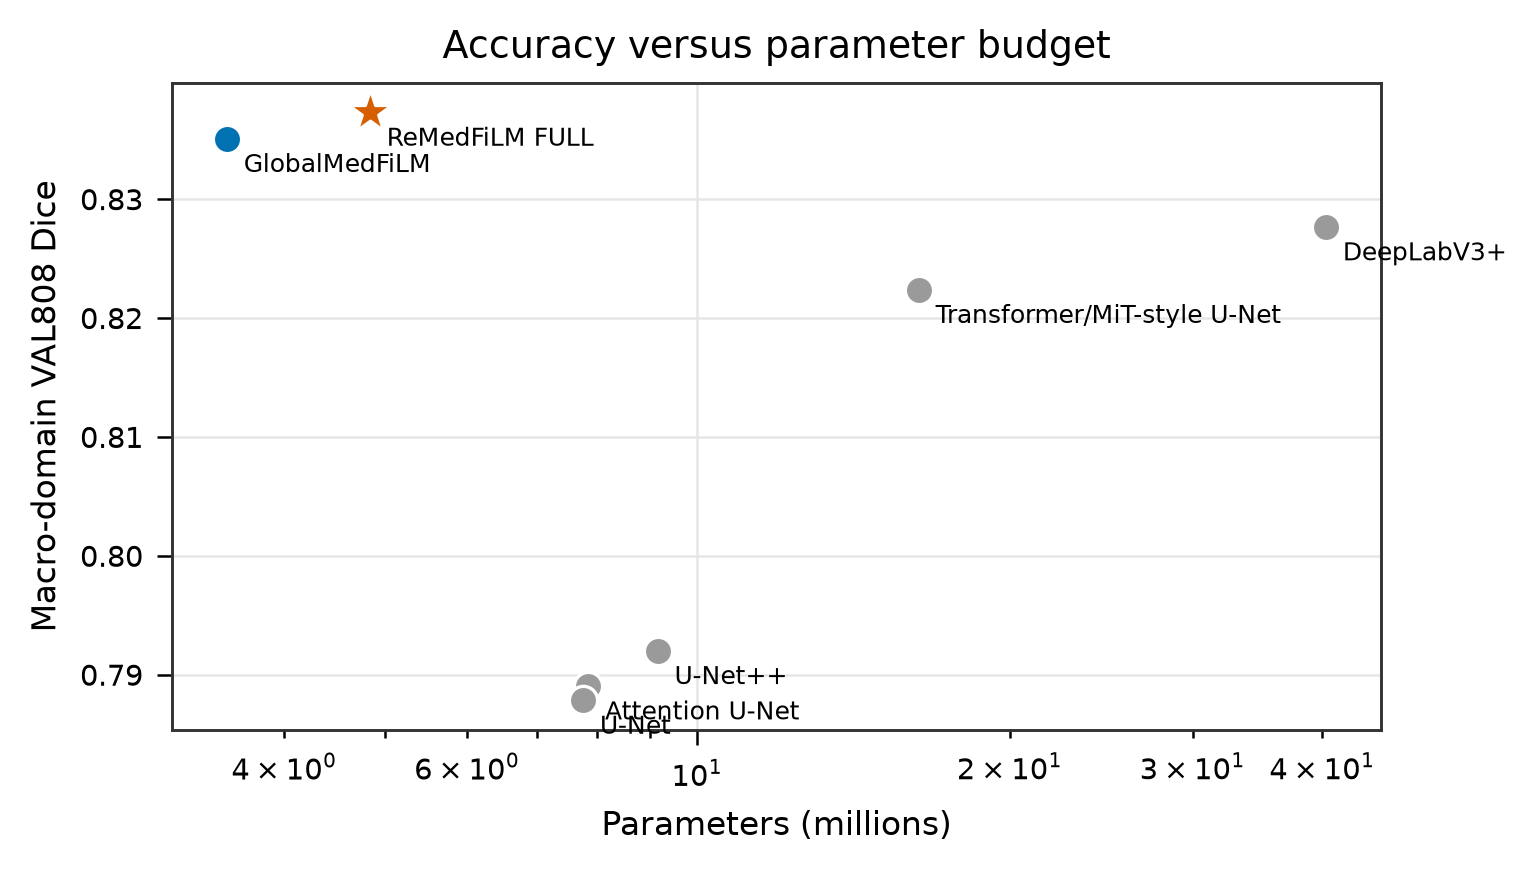

In [5]:
fig("Efficiency", "EFF01_accuracy_vs_compute", width=760)
fig("Efficiency", "EFF03_accuracy_vs_parameters", width=620)

## 11.3 Latency, with its exact meaning

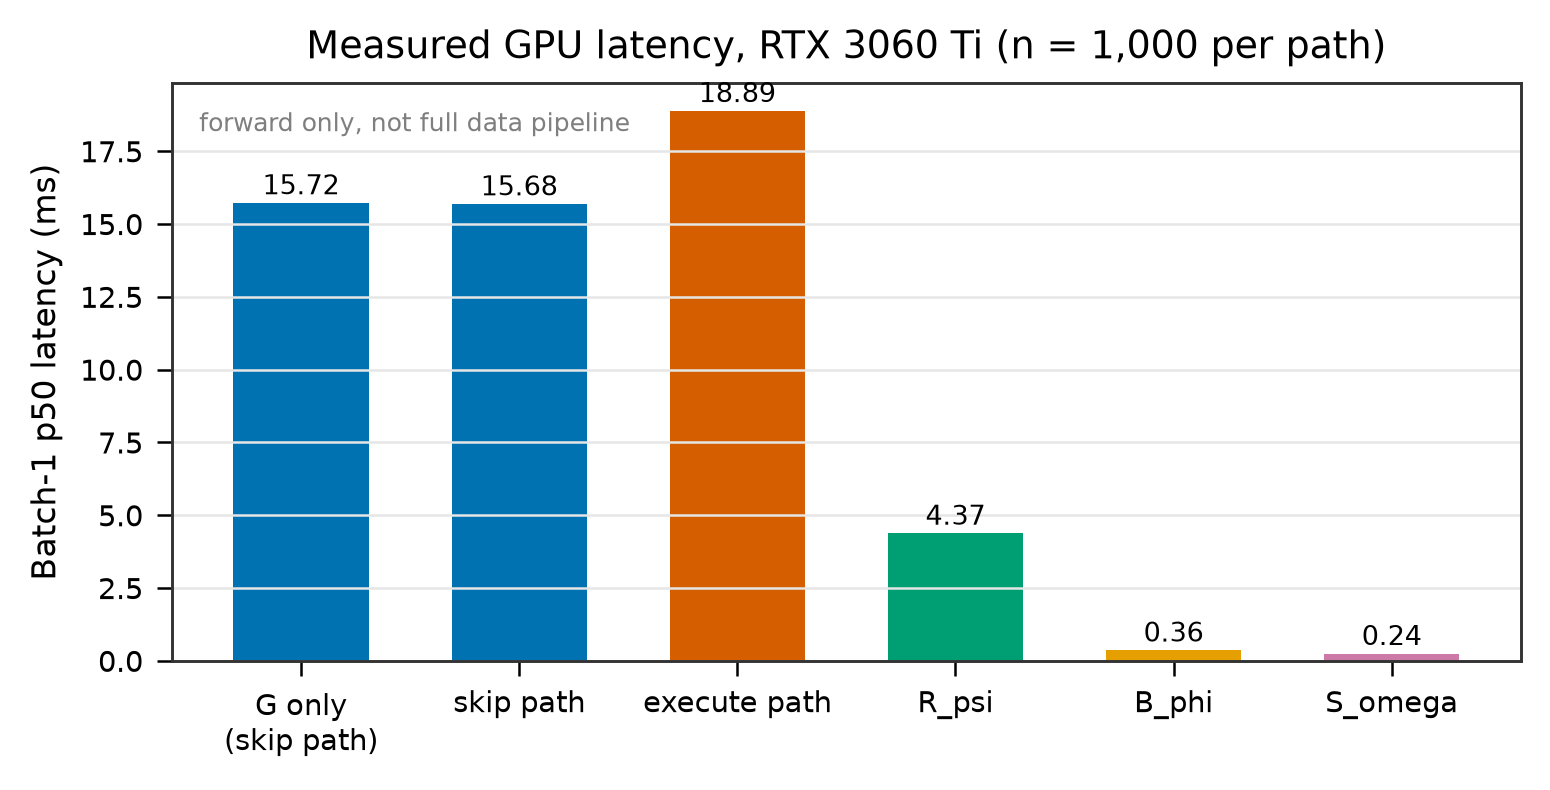

In [6]:
fig("Efficiency", "EFF02_latency_breakdown", width=700)

In [7]:
eff34 = json.loads((REPO / "reports/audits/phase34_efficiency_result_v1_4.json").read_text(encoding="utf-8"))
lat = eff34["MEASURED_HARDWARE_SPECIFIC_RUNTIME_PROFILE"]["batch1_latency_v1_4"]
for k in ("GLOBAL_ONLY_C1", "SKIP_CONTROLLED_PATH", "EXECUTE_CONTROLLED_PATH",
          "R_PSI_COMPONENT", "B_PHI_COMPONENT", "S_OMEGA_COMPONENT"):
    print(f"  {k:24s} p50 = {lat[k]['p50_ms']:.3f} ms  (n={lat[k]['n']})")

  GLOBAL_ONLY_C1           p50 = 15.721 ms  (n=1000)
  SKIP_CONTROLLED_PATH     p50 = 15.685 ms  (n=1000)
  EXECUTE_CONTROLLED_PATH  p50 = 18.887 ms  (n=1000)
  R_PSI_COMPONENT          p50 = 4.374 ms  (n=1000)
  B_PHI_COMPONENT          p50 = 0.361 ms  (n=1000)
  S_OMEGA_COMPONENT        p50 = 0.244 ms  (n=1000)


## 11.4 Four different things called "compute"

| Quantity | Value | Meaning |
|---|---|---|
| Analytical GMACs (G) | 31.5517 | closed-form Conv2d/Linear count, **lower bound** |
| Expected conditional GMACs (FULL) | 32.4379 | routing-weighted |
| Always-refine GMACs | 34.7824 | upper bound if every case is refined |
| Measured batch-1 p50 | 15.72 / 18.89 ms | GPU forward only, RTX 3060 Ti, n = 1,000 |
| Full-pipeline latency | **NOT_RECORDED** | preprocessing and I/O excluded |

The 18.89 ms figure is the **execute-path forward**, not clinical inference speed.

In [8]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
